# TCC: Previsão de Inadimplência em Concessão de Crédito
**Metodologia:** CRISP-DM

## Fases 4 e 5: Modelagem Preditiva e Avaliação (*Modeling & Evaluation*)

Este *notebook* dá continuidade à metodologia CRISP-DM. Após o entendimento e a preparação matemática dos dados (Fases 1, 2 e 3) realizados nos arquivos anteriores, o foco agora é treinar os algoritmos de *Machine Learning* e avaliar o seu desempenho.

Com base na fundamentação do projeto, aplicaremos o **Aprendizado Sensível ao Custo** (*Cost-Sensitive Learning*) para lidar com o desbalanceamento da classe alvo (80% adimplentes / 20% inadimplentes). Iniciaremos com a Regressão Logística para estabelecer a nossa linha de base (*baseline*) e avançaremos para os métodos baseados em árvores (Random Forest e XGBoost).

## 1. Importação de Bibliotecas e Carregamento dos Dados
Nesta etapa inicial, carregamos as ferramentas matemáticas do Scikit-Learn e as matrizes otimizadas em Parquet (Treino, Validação e Teste) geradas ao final da etapa de Preparação de Dados.

In [1]:
# Importacao das bibliotecas de modelagem preditiva e metricas
import polars as pl
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    average_precision_score # PR-AUC
)

# Importacao das bibliotecas visuais para a Matriz de Confusao
import matplotlib.pyplot as plt
import seaborn as sns

# FUNCAO PADRONIZADA DE AVALIACAO
def evaluate_classification(y_true, y_pred, y_pred_proba, model_name="Modelo"):
    """Calcula as metricas e plota a Matriz de Confusao."""
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    pr_auc = average_precision_score(y_true, y_pred_proba)
    
    print(f"--- Resultados: {model_name} ---")
    print(f"PR-AUC  : {pr_auc:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Recall  : {rec:.4f}")
    print(f"Precisao: {prec:.4f}")
    print(f"Acuracia: {acc:.4f}\n")
    
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Adimplente (0)', 'Inadimplente (1)'], 
                yticklabels=['Adimplente (0)', 'Inadimplente (1)'])
    plt.ylabel('Classe Real (Actual value)')
    plt.xlabel('Classe Predita (Predicted value)')
    plt.title(f'Matriz de Confusao - {model_name}')
    plt.show()


# PREPARACAO DOS DADOS
# Carregamento otimizado dos ficheiros particionados
df_train = pl.read_parquet('DataSet_Loan/df_treino.parquet')
df_val = pl.read_parquet('DataSet_Loan/df_val.parquet')
df_test = pl.read_parquet('DataSet_Loan/df_teste.parquet')

# Separacao entre variaveis preditivas (X) e a variavel alvo (y)
X_train = df_train.drop('target').to_pandas()
y_train = df_train.select('target').to_pandas().squeeze()

X_val = df_val.drop('target').to_pandas()
y_val = df_val.select('target').to_pandas().squeeze()

X_test = df_test.drop('target').to_pandas()
y_test = df_test.select('target').to_pandas().squeeze()

## 2. Regressão Logística (*Baseline*)

A **Regressão Logística** é utilizada como modelo de linha de base (*baseline*). Por ser um algoritmo estatístico de natureza linear, seu objetivo é estabelecer um referencial de desempenho para comparação com os modelos de *ensemble learning*.


### 2.1. Treinamento do Modelo

Nesta etapa, o modelo é treinado com o conjunto de treino e avaliado no conjunto de validação. Como a variável alvo apresenta desbalanceamento, utiliza-se `class_weight='balanced'`. As variáveis são padronizadas com `StandardScaler`, pois a Regressão Logística é sensível à escala dos atributos.

--- Resultados: Regressao Logistica ---
PR-AUC  : 0.3743
F1-score: 0.4268
Recall  : 0.6525
Precisao: 0.3171
Acuracia: 0.6460



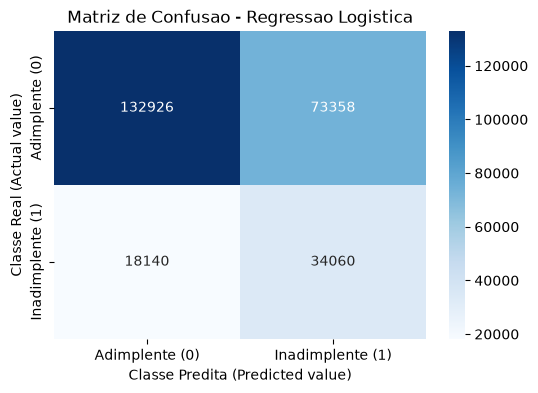

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", random_state=42, max_iter=2000)
)

log_reg.fit(X_train, y_train)

y_pred_val_lr = log_reg.predict(X_val)
y_pred_proba_val_lr = log_reg.predict_proba(X_val)[:, 1]

evaluate_classification(
    y_val,
    y_pred_val_lr, 
    y_pred_proba_val_lr,
    model_name="Regressao Logistica"
)

## 3. Random Forest

Avançando para os modelos de *ensemble learning*, a segunda abordagem avaliada é o algoritmo **Random Forest**. Por ser um método baseado na construção de múltiplas árvores de decisão com menor correlação entre si, utilizando a estratégia de *bagging*, esse modelo possui alta capacidade para mapear relações não lineares complexas entre os atributos dos clientes, algo que o modelo linear de *baseline* não consegue realizar nativamente.

Para manter a coerência metodológica e lidar com o desbalanceamento das classes, a técnica de **Cost-Sensitive Learning** é preservada por meio do parâmetro `class_weight='balanced'`. Além disso, para mitigar o risco de sobreajuste (*overfitting*) inerente aos modelos baseados em árvores, a profundidade máxima das árvores (`max_depth`) é inicialmente controlada.

Ao contrário da Regressão Logística, algoritmos baseados em árvores não dependem da escala das variáveis. Por isso, o Random Forest dispensa o uso de padronizadores como o `StandardScaler`.

### 3.1. Treinamento do Modelo

Nesta etapa, é treinada uma configuração inicial do Random Forest utilizando o conjunto de treino. O modelo é avaliado no conjunto de validação, que será utilizado como referência para as etapas posteriores de ajuste.

--- Resultados: Random Forest ---
PR-AUC  : 0.3802
F1-score: 0.4281
Recall  : 0.6725
Precisao: 0.3139
Acuracia: 0.6371



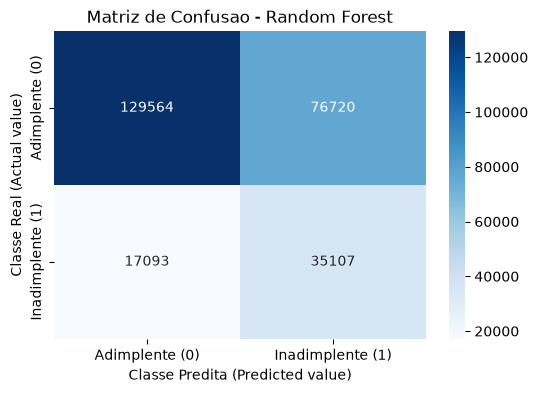

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# max_depth=10 atua como controle inicial contra overfitting (sobreajuste)
# n_jobs=-1 paraleliza o processamento para maior velocidade
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Treinamento
rf_model.fit(X_train, y_train)

# Geração das predições e probabilidades no conjunto de validação
y_pred_val_rf = rf_model.predict(X_val)
y_pred_proba_val_rf = rf_model.predict_proba(X_val)[:, 1]

# Chamada da função para exibir as métricas e o gráfico
evaluate_classification(
    y_val,
    y_pred_val_rf,
    y_pred_proba_val_rf,
    model_name="Random Forest"
)

## 5. Registro e Comparação dos Modelos

Nesta etapa, são reunidos os resultados obtidos pelos modelos durante o desenvolvimento, utilizando exclusivamente o conjunto de validação. O objetivo é comparar o desempenho da Regressão Logística, utilizada como modelo baseline, com as versões inicial e ajustada do Random Forest e do XGBoost.

As métricas consideradas são PR-AUC, F1-score, Recall, precisão e acurácia. Essa comparação orienta a seleção dos modelos que serão submetidos à avaliação final no conjunto de teste Out-of-Time (OOT).

O conjunto OOT permanece isolado nesta etapa e não é utilizado para escolher modelos ou hiperparâmetros.

In [ ]:
# Registro dos resultados baseline na validação
baseline_lr_results = {
    "Modelo": "Regressão Logística - Baseline",
    "PR-AUC": 0.3743,
    "F1-score": 0.4268,
    "Recall": 0.6525,
    "Precisao": 0.3171,
    "Acuracia": 0.6460,
}

baseline_rf_results = {
    "Modelo": "Random Forest - Baseline",
    "PR-AUC": 0.3802,
    "F1-score": 0.4281,
    "Recall": 0.6725,
    "Precisao": 0.3139,
    "Acuracia": 0.6371,
}

baseline_rf_params = {
    "n_estimators": 100,
    "max_depth": 10,
    "class_weight": "balanced",
    "random_state": 42,
}

baseline_comparison = pd.DataFrame([
    baseline_lr_results,
    baseline_rf_results,
])

baseline_comparison

,Modelo,PR-AUC,F1-score,Recall,Precisao,Acuracia
0,Regressão Logística - Baseline,0.3743,0.4268,0.6525,0.3171,0.6460
1,Random Forest - Baseline,0.3802,0.4281,0.6725,0.3139,0.6371
